In [ ]:
# ================================================================
# PHASE 3D — CELL 1
# MOUNT GOOGLE DRIVE
# ================================================================

from google.colab import drive

drive.mount(
    "/content/drive"
)

print(
    "✓ Google Drive mounted."
)

Mounted at /content/drive
✓ Google Drive mounted.


In [ ]:
# ================================================================
# PHASE 3D — CELL 2
# IMPORTS + REPRODUCIBILITY
# ================================================================

import os
import json
import random
import hashlib
import warnings

from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import joblib


from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)


# ---------------------------------------------------------------
# REPRODUCIBILITY
# ---------------------------------------------------------------

SEED = 42

os.environ[
    "PYTHONHASHSEED"
] = str(SEED)

random.seed(
    SEED
)

np.random.seed(
    SEED
)


warnings.filterwarnings(
    "ignore"
)


print(
    "✓ Imports complete."
)

print(
    "✓ Random seed:",
    SEED
)

✓ Imports complete.
✓ Random seed: 42


In [ ]:
# ================================================================
# PHASE 3D — CELL 3
# PROJECT PATHS
# ================================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CAMUS_FINAL"
)


PHASE2_DIR = (
    PROJECT_DIR /
    "phase2_quantitative"
)


PHASE3_DIR = (
    PROJECT_DIR /
    "phase3_classification"
)


PHASE3A_DIR = (
    PHASE3_DIR /
    "phase3A_label_audit"
)


PHASE3B_DIR = (
    PHASE3_DIR /
    "phase3B_direct_baseline"
)


PHASE3C_DIR = (
    PHASE3_DIR /
    "phase3C_classifier_development"
)


PHASE3D_DIR = (
    PHASE3_DIR /
    "phase3D_final_evaluation"
)


# ---------------------------------------------------------------
# PHASE 3D OUTPUT DIRECTORIES
# ---------------------------------------------------------------

PHASE3D_CONFIG_DIR = (
    PHASE3D_DIR /
    "configs"
)

PHASE3D_TABLE_DIR = (
    PHASE3D_DIR /
    "tables"
)

PHASE3D_PLOT_DIR = (
    PHASE3D_DIR /
    "plots"
)


for directory in [

    PHASE3D_CONFIG_DIR,
    PHASE3D_TABLE_DIR,
    PHASE3D_PLOT_DIR

]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ---------------------------------------------------------------
# VERIFY PREVIOUS PHASES
# ---------------------------------------------------------------

assert PHASE3A_DIR.exists(), (
    "Phase 3A directory missing."
)

assert PHASE3B_DIR.exists(), (
    "Phase 3B directory missing."
)

assert PHASE3C_DIR.exists(), (
    "Phase 3C directory missing."
)


print("=" * 80)
print("PHASE 3D DIRECTORY SETUP")
print("=" * 80)


print(
    "\nPhase 3D directory:"
)

print(
    PHASE3D_DIR
)


print(
    "\n✓ configs/"
)

print(
    "✓ tables/"
)

print(
    "✓ plots/"
)


print(
    "\n✓ Phase 3A found."
)

print(
    "✓ Phase 3B found."
)

print(
    "✓ Phase 3C found."
)

PHASE 3D DIRECTORY SETUP

Phase 3D directory:
/content/drive/MyDrive/CAMUS_FINAL/phase3_classification/phase3D_final_evaluation

✓ configs/
✓ tables/
✓ plots/

✓ Phase 3A found.
✓ Phase 3B found.
✓ Phase 3C found.


In [ ]:
# ================================================================
# PHASE 3D — CELL 4
# VERIFY ALL REQUIRED FROZEN INPUT ARTIFACTS
# ================================================================

# ---------------------------------------------------------------
# PHASE 3A
# ---------------------------------------------------------------

PHASE3A_LABELS_PATH = (
    PHASE3A_DIR /
    "tables" /
    "phase3_reference_EF_labels.csv"
)


PHASE3A_DECISION_PATH = (
    PHASE3A_DIR /
    "configs" /
    "phase3A_classification_target_decision.json"
)


# ---------------------------------------------------------------
# PHASE 3B
# ---------------------------------------------------------------

PHASE3B_RECORD_PATH = (
    PHASE3B_DIR /
    "configs" /
    "phase3B_direct_baseline_record.json"
)


# ---------------------------------------------------------------
# PHASE 3C
# ---------------------------------------------------------------

PHASE3C_RECORD_PATH = (
    PHASE3C_DIR /
    "configs" /
    "phase3C_development_record.json"
)


PHASE3C_PROTOCOL_PATH = (
    PHASE3C_DIR /
    "configs" /
    "phase3C_predefined_protocol.json"
)


PHASE3C_MODEL_PATH = (
    PHASE3C_DIR /
    "models" /
    "phase3C_selected_logistic_regression.joblib"
)


PHASE3C_VALIDATION_RESULTS_PATH = (
    PHASE3C_DIR /
    "tables" /
    "phase3C_validation_model_comparison.csv"
)


# ---------------------------------------------------------------
# PHASE 2B
# ---------------------------------------------------------------

PHASE2B_TEST_TABLE_PATH = (
    PHASE2_DIR /
    "phase2B_final_evaluation" /
    "tables" /
    "final_test_quantitative_measurements.csv"
)


PHASE2_FINAL_RECORD_PATH = (
    PHASE2_DIR /
    "PHASE2_FINAL_RECORD.json"
)


# ---------------------------------------------------------------
# CHECK
# ---------------------------------------------------------------

required_artifacts = {

    "Phase 3A labels":
        PHASE3A_LABELS_PATH,

    "Phase 3A target decision":
        PHASE3A_DECISION_PATH,

    "Phase 3B baseline record":
        PHASE3B_RECORD_PATH,

    "Phase 3C predefined protocol":
        PHASE3C_PROTOCOL_PATH,

    "Phase 3C development record":
        PHASE3C_RECORD_PATH,

    "Phase 3C frozen classifier":
        PHASE3C_MODEL_PATH,

    "Phase 3C validation comparison":
        PHASE3C_VALIDATION_RESULTS_PATH,

    "Phase 2B final test measurements":
        PHASE2B_TEST_TABLE_PATH,

    "Phase 2 final record":
        PHASE2_FINAL_RECORD_PATH
}


print("=" * 80)
print("PHASE 3D — FROZEN INPUT VERIFICATION")
print("=" * 80)


all_found = True


for name, path in (
    required_artifacts.items()
):

    exists = path.exists()

    print(
        f"{'✓ FOUND' if exists else '✗ MISSING'}"
        f" | {name}"
    )


    if not exists:

        print(
            "          ",
            path
        )

        all_found = False


print(
    "\n" + "=" * 80
)


if not all_found:

    raise FileNotFoundError(
        "One or more frozen artifacts are missing. "
        "Do not continue Phase 3D."
    )


print(
    "✓ All required frozen artifacts found."
)

print(
    "✓ Safe to verify the Phase 3C freeze."
)

PHASE 3D — FROZEN INPUT VERIFICATION
✓ FOUND | Phase 3A labels
✓ FOUND | Phase 3A target decision
✓ FOUND | Phase 3B baseline record
✓ FOUND | Phase 3C predefined protocol
✓ FOUND | Phase 3C development record
✓ FOUND | Phase 3C frozen classifier
✓ FOUND | Phase 3C validation comparison
✓ FOUND | Phase 2B final test measurements
✓ FOUND | Phase 2 final record

✓ All required frozen artifacts found.
✓ Safe to verify the Phase 3C freeze.


In [ ]:
# ================================================================
# PHASE 3D — CELL 5
# VERIFY FROZEN PHASE 3C DEVELOPMENT RECORD + MODEL HASH
# ================================================================

def calculate_sha256(
    file_path,
    chunk_size=1024 * 1024
):

    sha256 = hashlib.sha256()

    with open(
        file_path,
        "rb"
    ) as file:

        while True:

            chunk = file.read(
                chunk_size
            )

            if not chunk:
                break

            sha256.update(
                chunk
            )

    return sha256.hexdigest()


# ---------------------------------------------------------------
# LOAD FROZEN PHASE 3C RECORD
# ---------------------------------------------------------------

with open(
    PHASE3C_RECORD_PATH,
    "r"
) as file:

    phase3C_record = json.load(
        file
    )


# ---------------------------------------------------------------
# VERIFY FROZEN STATUS
# ---------------------------------------------------------------

assert (
    phase3C_record[
        "status"
    ]
    ==
    "DEVELOPMENT_COMPLETE_AND_FROZEN"
), (
    "Phase 3C record is not marked frozen."
)


assert (
    phase3C_record[
        "phase3C_frozen"
    ]
    is True
), (
    "Phase 3C frozen flag is not True."
)


assert (
    phase3C_record[
        "development_data"
    ][
        "test_patients_used"
    ]
    ==
    0
), (
    "Phase 3C record indicates test data "
    "were used during development."
)


# ---------------------------------------------------------------
# RECOVER SELECTED FEATURE SET
# ---------------------------------------------------------------

SELECTED_FEATURE_SET = (
    phase3C_record[
        "selection"
    ][
        "selected_feature_set"
    ]
)


SELECTED_FEATURES = (
    phase3C_record[
        "selection"
    ][
        "selected_features"
    ]
)


EXPECTED_FEATURES = [

    "PRED_ED_area_mm2",
    "PRED_ES_area_mm2",

    "PRED_ED_length_mm",
    "PRED_ES_length_mm",

    "PRED_EDV_ml",
    "PRED_ESV_ml",

    "PRED_SV_ml",
    "PRED_EF_pct"
]


assert (
    SELECTED_FEATURE_SET
    ==
    "F3_full_quantitative"
)


assert (
    SELECTED_FEATURES
    ==
    EXPECTED_FEATURES
), (
    "Frozen Phase 3C feature order does "
    "not match expected F3 order."
)


# ---------------------------------------------------------------
# VERIFY MODEL HASH
# ---------------------------------------------------------------

EXPECTED_MODEL_SHA256 = (
    phase3C_record[
        "selected_model_artifact"
    ][
        "sha256"
    ]
)


ACTUAL_MODEL_SHA256 = (
    calculate_sha256(
        PHASE3C_MODEL_PATH
    )
)


assert (
    ACTUAL_MODEL_SHA256
    ==
    EXPECTED_MODEL_SHA256
), (
    "Phase 3C classifier SHA-256 mismatch."
)


print("=" * 80)
print("PHASE 3C FREEZE VERIFICATION")
print("=" * 80)


print(
    "\nStatus:",
    phase3C_record["status"]
)


print(
    "Selected feature set:",
    SELECTED_FEATURE_SET
)


print(
    "Number of features:",
    len(
        SELECTED_FEATURES
    )
)


print(
    "\nFrozen feature order:"
)

for index, feature in enumerate(
    SELECTED_FEATURES,
    start=1
):

    print(
        f"{index}. {feature}"
    )


print(
    "\nExpected model SHA-256:"
)

print(
    EXPECTED_MODEL_SHA256
)


print(
    "\nActual model SHA-256:"
)

print(
    ACTUAL_MODEL_SHA256
)


print(
    "\n✓ Phase 3C development record verified."
)

print(
    "✓ Frozen model hash verified."
)

print(
    "✓ Test patients used during Phase 3C: 0."
)

PHASE 3C FREEZE VERIFICATION

Status: DEVELOPMENT_COMPLETE_AND_FROZEN
Selected feature set: F3_full_quantitative
Number of features: 8

Frozen feature order:
1. PRED_ED_area_mm2
2. PRED_ES_area_mm2
3. PRED_ED_length_mm
4. PRED_ES_length_mm
5. PRED_EDV_ml
6. PRED_ESV_ml
7. PRED_SV_ml
8. PRED_EF_pct

Expected model SHA-256:
2ab03a57d0655aa557d0f3ce30c7438c84baa8e068575ba0ebc2ead3344194e6

Actual model SHA-256:
2ab03a57d0655aa557d0f3ce30c7438c84baa8e068575ba0ebc2ead3344194e6

✓ Phase 3C development record verified.
✓ Frozen model hash verified.
✓ Test patients used during Phase 3C: 0.


In [ ]:
# ================================================================
# PHASE 3D — CELL 6
# LOAD FROZEN CLASSIFIER — NO FITTING
# ================================================================

frozen_phase3C_classifier = (
    joblib.load(
        PHASE3C_MODEL_PATH
    )
)


# ---------------------------------------------------------------
# VERIFY PIPELINE STRUCTURE
# ---------------------------------------------------------------

assert hasattr(
    frozen_phase3C_classifier,
    "named_steps"
)


assert (
    "scaler"
    in
    frozen_phase3C_classifier.named_steps
)


assert (
    "classifier"
    in
    frozen_phase3C_classifier.named_steps
)


frozen_scaler = (
    frozen_phase3C_classifier
    .named_steps[
        "scaler"
    ]
)


frozen_logistic_classifier = (
    frozen_phase3C_classifier
    .named_steps[
        "classifier"
    ]
)


assert (
    frozen_scaler.n_features_in_
    ==
    8
)


assert (
    frozen_logistic_classifier.n_features_in_
    ==
    8
)


print("=" * 80)
print("FROZEN CLASSIFIER STRUCTURE")
print("=" * 80)


print(
    "\nPipeline type:",
    type(
        frozen_phase3C_classifier
    ).__name__
)


print(
    "Scaler:",
    type(
        frozen_scaler
    ).__name__
)


print(
    "Classifier:",
    type(
        frozen_logistic_classifier
    ).__name__
)


print(
    "\nExpected input features:",
    frozen_scaler.n_features_in_
)


print(
    "Classifier classes:",
    list(
        frozen_logistic_classifier.classes_
    )
)


print(
    "\n✓ Frozen classifier loaded."
)

print(
    "✓ No fit() operation performed."
)

print(
    "✓ Model expects exactly 8 features."
)

FROZEN CLASSIFIER STRUCTURE

Pipeline type: Pipeline
Scaler: StandardScaler
Classifier: LogisticRegression

Expected input features: 8
Classifier classes: ['Higher_EF', 'Intermediate_EF', 'Lower_EF']

✓ Frozen classifier loaded.
✓ No fit() operation performed.
✓ Model expects exactly 8 features.


In [ ]:
# ================================================================
# PHASE 3D — CELL 7
# CONSTRUCT LOCKED 50-PATIENT EVALUATION TABLE
# ================================================================

# ---------------------------------------------------------------
# LOAD PHASE 3A LABELS
# ---------------------------------------------------------------

phase3A_labels_df = pd.read_csv(
    PHASE3A_LABELS_PATH
)


test_labels_df = (
    phase3A_labels_df[
        phase3A_labels_df[
            "split"
        ]
        ==
        "test"
    ]
    .copy()
    .reset_index(drop=True)
)


# ---------------------------------------------------------------
# LOAD FROZEN PHASE 2B TEST MEASUREMENTS
# ---------------------------------------------------------------

phase2B_test_df = pd.read_csv(
    PHASE2B_TEST_TABLE_PATH
)


print("=" * 80)
print("LOCKED EVALUATION DATA")
print("=" * 80)


print(
    "\nPhase 3A test labels:",
    len(
        test_labels_df
    )
)


print(
    "Phase 2B test measurements:",
    len(
        phase2B_test_df
    )
)


# ---------------------------------------------------------------
# BASIC CHECKS
# ---------------------------------------------------------------

assert len(
    test_labels_df
) == 50


assert len(
    phase2B_test_df
) == 50


assert (
    test_labels_df[
        "patient_id"
    ].nunique()
    ==
    50
)


assert (
    phase2B_test_df[
        "patient_id"
    ].nunique()
    ==
    50
)


# ---------------------------------------------------------------
# VERIFY EXACT SAME PATIENT SET
# ---------------------------------------------------------------

label_patient_set = set(
    test_labels_df[
        "patient_id"
    ]
)


measurement_patient_set = set(
    phase2B_test_df[
        "patient_id"
    ]
)


assert (
    label_patient_set
    ==
    measurement_patient_set
), (
    "Phase 3A test patients and Phase 2B "
    "measurement patients do not match."
)


# ---------------------------------------------------------------
# SELECT ONLY REQUIRED FROZEN QUANTITATIVE FEATURES
# ---------------------------------------------------------------

required_measurement_columns = [

    "patient_id",

    "ED_PRED_area_mm2",
    "ES_PRED_area_mm2",

    "ED_PRED_length_mm",
    "ES_PRED_length_mm",

    "ED_PRED_volume_ml",
    "ES_PRED_volume_ml",

    "PRED_SV_ml",
    "PRED_EF_pct"
]


missing_measurement_columns = [

    column
    for column
    in required_measurement_columns

    if column
    not in phase2B_test_df.columns
]


assert (
    len(
        missing_measurement_columns
    )
    ==
    0
), (
    "Missing Phase 2B columns: "
    f"{missing_measurement_columns}"
)


# ---------------------------------------------------------------
# RENAME PHASE 2B NAMES TO FROZEN PHASE 3C FEATURE NAMES
# ---------------------------------------------------------------

test_measurements_df = (

    phase2B_test_df[
        required_measurement_columns
    ]

    .rename(
        columns={

            "ED_PRED_area_mm2":
                "PRED_ED_area_mm2",

            "ES_PRED_area_mm2":
                "PRED_ES_area_mm2",

            "ED_PRED_length_mm":
                "PRED_ED_length_mm",

            "ES_PRED_length_mm":
                "PRED_ES_length_mm",

            "ED_PRED_volume_ml":
                "PRED_EDV_ml",

            "ES_PRED_volume_ml":
                "PRED_ESV_ml"
        }
    )
)


# ---------------------------------------------------------------
# MERGE LABELS + FEATURES
# ---------------------------------------------------------------

phase3D_test_df = (

    test_labels_df[
        [
            "patient_id",
            "reference_EF_pct",
            "reference_EF_class"
        ]
    ]

    .merge(
        test_measurements_df,
        on="patient_id",
        how="inner",
        validate="one_to_one"
    )

    .reset_index(drop=True)
)


assert len(
    phase3D_test_df
) == 50


print(
    "\n✓ Exact patient sets match."
)

print(
    "✓ Locked evaluation table constructed."
)

print(
    "✓ Number of evaluation patients:",
    len(
        phase3D_test_df
    )
)

LOCKED EVALUATION DATA

Phase 3A test labels: 50
Phase 2B test measurements: 50

✓ Exact patient sets match.
✓ Locked evaluation table constructed.
✓ Number of evaluation patients: 50


In [ ]:
# ================================================================
# PHASE 3D — CELL 8
# FINAL TEST FEATURE INTEGRITY GATE
# ================================================================

CLASS_ORDER = [

    "Lower_EF",
    "Intermediate_EF",
    "Higher_EF"
]


print("=" * 80)
print("PHASE 3D — FINAL PRE-PREDICTION INTEGRITY GATE")
print("=" * 80)


# ---------------------------------------------------------------
# VERIFY ALL SELECTED FEATURES
# ---------------------------------------------------------------

missing_features = [

    feature
    for feature
    in SELECTED_FEATURES

    if feature
    not in phase3D_test_df.columns
]


assert (
    len(
        missing_features
    )
    ==
    0
), (
    f"Missing selected features: "
    f"{missing_features}"
)


# ---------------------------------------------------------------
# BUILD EXACT FEATURE MATRIX
# ---------------------------------------------------------------

X_test = (

    phase3D_test_df[
        SELECTED_FEATURES
    ]

    .to_numpy(
        dtype=np.float64
    )
)


y_test = (

    phase3D_test_df[
        "reference_EF_class"
    ]

    .to_numpy()
)


# ---------------------------------------------------------------
# DIMENSION CHECKS
# ---------------------------------------------------------------

assert (
    X_test.shape
    ==
    (
        50,
        8
    )
)


assert len(
    y_test
) == 50


# ---------------------------------------------------------------
# FINITE FEATURE CHECK
# ---------------------------------------------------------------

assert np.isfinite(
    X_test
).all(), (
    "Non-finite values detected in test features."
)


# ---------------------------------------------------------------
# LABEL CHECK
# ---------------------------------------------------------------

assert set(
    np.unique(
        y_test
    )
) == set(
    CLASS_ORDER
)


# ---------------------------------------------------------------
# CLASS DISTRIBUTION
# ---------------------------------------------------------------

test_class_counts = (

    phase3D_test_df[
        "reference_EF_class"
    ]

    .value_counts()

    .reindex(
        CLASS_ORDER
    )
)


print(
    "\nFeature matrix shape:",
    X_test.shape
)


print(
    "\nFrozen feature order:"
)


for index, feature in enumerate(
    SELECTED_FEATURES,
    start=1
):

    print(
        f"{index}. {feature}"
    )


print(
    "\nLocked evaluation class distribution:"
)

print(
    test_class_counts.to_string()
)


print(
    "\nNon-finite feature values:",
    int(
        (
            ~np.isfinite(
                X_test
            )
        ).sum()
    )
)


print("\n" + "=" * 80)


print(
    "✓ PRE-PREDICTION INTEGRITY CHECK PASSED."
)

print(
    "✓ 50 × 8 locked feature matrix ready."
)

print(
    "✓ Frozen classifier has not been modified."
)

print(
    "✓ No test-driven tuning has been performed."
)

PHASE 3D — FINAL PRE-PREDICTION INTEGRITY GATE

Feature matrix shape: (50, 8)

Frozen feature order:
1. PRED_ED_area_mm2
2. PRED_ES_area_mm2
3. PRED_ED_length_mm
4. PRED_ES_length_mm
5. PRED_EDV_ml
6. PRED_ESV_ml
7. PRED_SV_ml
8. PRED_EF_pct

Locked evaluation class distribution:
reference_EF_class
Lower_EF           16
Intermediate_EF    14
Higher_EF          20

Non-finite feature values: 0

✓ PRE-PREDICTION INTEGRITY CHECK PASSED.
✓ 50 × 8 locked feature matrix ready.
✓ Frozen classifier has not been modified.
✓ No test-driven tuning has been performed.


In [ ]:
# ================================================================
# PHASE 3D — CELL 9
# ONE-TIME LOCKED TEST PREDICTION
# ================================================================

print("=" * 80)
print("PHASE 3D — ONE-TIME LOCKED PREDICTION")
print("=" * 80)


# ---------------------------------------------------------------
# IMPORTANT:
# No fit(), tuning, calibration, or threshold modification occurs.
# ---------------------------------------------------------------

y_test_pred = (
    frozen_phase3C_classifier.predict(
        X_test
    )
)


# ---------------------------------------------------------------
# OPTIONAL CLASS PROBABILITIES
# These are outputs only — they will NOT be used for tuning.
# ---------------------------------------------------------------

y_test_prob = (
    frozen_phase3C_classifier.predict_proba(
        X_test
    )
)


# ---------------------------------------------------------------
# BASIC CHECKS
# ---------------------------------------------------------------

assert len(
    y_test_pred
) == 50


assert y_test_prob.shape == (
    50,
    3
)


assert set(
    np.unique(
        y_test_pred
    )
).issubset(
    set(
        CLASS_ORDER
    )
)


assert np.allclose(
    y_test_prob.sum(axis=1),
    1.0
)


print(
    "\nPredictions generated:",
    len(
        y_test_pred
    )
)


print(
    "Probability matrix:",
    y_test_prob.shape
)


print(
    "\nPredicted class distribution:"
)


predicted_class_counts = (

    pd.Series(
        y_test_pred
    )

    .value_counts()

    .reindex(
        CLASS_ORDER,
        fill_value=0
    )
)


print(
    predicted_class_counts.to_string()
)


print("\n" + "=" * 80)

print(
    "✓ ONE-TIME LOCKED PREDICTION COMPLETE."
)

print(
    "✓ No retraining performed."
)

print(
    "✓ No test-driven adjustment performed."
)

PHASE 3D — ONE-TIME LOCKED PREDICTION

Predictions generated: 50
Probability matrix: (50, 3)

Predicted class distribution:
Lower_EF           19
Intermediate_EF    10
Higher_EF          21

✓ ONE-TIME LOCKED PREDICTION COMPLETE.
✓ No retraining performed.
✓ No test-driven adjustment performed.


In [ ]:
# ================================================================
# PHASE 3D — CELL 10
# FINAL LOCKED CLASSIFIER METRICS
# ================================================================

test_accuracy = (
    accuracy_score(
        y_test,
        y_test_pred
    )
)


test_balanced_accuracy = (
    balanced_accuracy_score(
        y_test,
        y_test_pred
    )
)


test_macro_f1 = (
    f1_score(
        y_test,
        y_test_pred,
        average="macro",
        zero_division=0
    )
)


test_weighted_f1 = (
    f1_score(
        y_test,
        y_test_pred,
        average="weighted",
        zero_division=0
    )
)


test_kappa = (
    cohen_kappa_score(
        y_test,
        y_test_pred
    )
)


test_correct = int(
    (
        y_test_pred
        ==
        y_test
    ).sum()
)


test_incorrect = int(
    (
        y_test_pred
        !=
        y_test
    ).sum()
)


print("=" * 80)
print("PHASE 3D — FINAL LOCKED CLASSIFIER PERFORMANCE")
print("=" * 80)


print(
    f"\nAccuracy          : "
    f"{test_accuracy:.4f}"
)


print(
    f"Balanced Accuracy : "
    f"{test_balanced_accuracy:.4f}"
)


print(
    f"Macro F1          : "
    f"{test_macro_f1:.4f}"
)


print(
    f"Weighted F1       : "
    f"{test_weighted_f1:.4f}"
)


print(
    f"Cohen Kappa       : "
    f"{test_kappa:.4f}"
)


print(
    f"\nCorrect           : "
    f"{test_correct}/50"
)


print(
    f"Incorrect         : "
    f"{test_incorrect}/50"
)


print("\n" + "=" * 80)

print(
    "✓ Final locked metrics calculated."
)

PHASE 3D — FINAL LOCKED CLASSIFIER PERFORMANCE

Accuracy          : 0.7000
Balanced Accuracy : 0.6732
Macro F1          : 0.6629
Weighted F1       : 0.6861
Cohen Kappa       : 0.5416

Correct           : 35/50
Incorrect         : 15/50

✓ Final locked metrics calculated.


In [ ]:
# ================================================================
# PHASE 3D — CELL 11
# CONFUSION MATRIX + PER-CLASS PERFORMANCE
# ================================================================

# ---------------------------------------------------------------
# CONFUSION MATRIX
# ---------------------------------------------------------------

test_confusion_matrix = (
    confusion_matrix(
        y_test,
        y_test_pred,
        labels=CLASS_ORDER
    )
)


test_confusion_df = pd.DataFrame(

    test_confusion_matrix,

    index=[
        f"True_{label}"
        for label in CLASS_ORDER
    ],

    columns=[
        f"Pred_{label}"
        for label in CLASS_ORDER
    ]
)


print("=" * 80)
print("PHASE 3D — CLASS-LEVEL PERFORMANCE")
print("=" * 80)


print(
    "\nConfusion matrix:"
)


display(
    test_confusion_df
)


# ---------------------------------------------------------------
# CLASSIFICATION REPORT
# ---------------------------------------------------------------

test_report = (
    classification_report(
        y_test,
        y_test_pred,
        labels=CLASS_ORDER,
        output_dict=True,
        zero_division=0
    )
)


test_per_class_records = []


for class_name in CLASS_ORDER:

    metrics = (
        test_report[
            class_name
        ]
    )


    test_per_class_records.append({

        "class":
            class_name,

        "precision":
            float(
                metrics[
                    "precision"
                ]
            ),

        "recall":
            float(
                metrics[
                    "recall"
                ]
            ),

        "f1":
            float(
                metrics[
                    "f1-score"
                ]
            ),

        "support":
            int(
                metrics[
                    "support"
                ]
            )
    })


test_per_class_df = (
    pd.DataFrame(
        test_per_class_records
    )
)


print(
    "\nPer-class performance:"
)


display(

    test_per_class_df.style.format({

        "precision":
            "{:.4f}",

        "recall":
            "{:.4f}",

        "f1":
            "{:.4f}"
    })
)


# ---------------------------------------------------------------
# SAVE
# ---------------------------------------------------------------

TEST_PER_CLASS_PATH = (
    PHASE3D_TABLE_DIR /
    "phase3D_final_per_class_metrics.csv"
)


TEST_CONFUSION_PATH = (
    PHASE3D_TABLE_DIR /
    "phase3D_final_confusion_matrix.csv"
)


test_per_class_df.to_csv(
    TEST_PER_CLASS_PATH,
    index=False
)


test_confusion_df.to_csv(
    TEST_CONFUSION_PATH
)


print(
    "\n✓ Confusion matrix saved."
)

print(
    "✓ Per-class metrics saved."
)

PHASE 3D — CLASS-LEVEL PERFORMANCE

Confusion matrix:


,Pred_Lower_EF,Pred_Intermediate_EF,Pred_Higher_EF
True_Lower_EF,13,2,1
True_Intermediate_EF,6,5,3
True_Higher_EF,0,3,17



Per-class performance:


,class,precision,recall,f1,support
0,Lower_EF,0.6842,0.8125,0.7429,16
1,Intermediate_EF,0.5000,0.3571,0.4167,14
2,Higher_EF,0.8095,0.8500,0.8293,20



✓ Confusion matrix saved.
✓ Per-class metrics saved.


In [ ]:
# ================================================================
# PHASE 3D — CELL 12
# FROZEN PHASE 3B BASELINE vs LEARNED PHASE 3C CLASSIFIER
# ================================================================

# ---------------------------------------------------------------
# LOAD PHASE 3B FROZEN RECORD
# ---------------------------------------------------------------

with open(
    PHASE3B_RECORD_PATH,
    "r"
) as file:

    phase3B_record = (
        json.load(
            file
        )
    )


print("=" * 80)
print("DIRECT BASELINE vs LEARNED CLASSIFIER")
print("=" * 80)


# ---------------------------------------------------------------
# INSPECT AVAILABLE RECORD STRUCTURE
# ---------------------------------------------------------------

print(
    "\nPhase 3B record status:",
    phase3B_record.get(
        "status",
        "NOT_RECORDED"
    )
)


# ---------------------------------------------------------------
# KNOWN FROZEN PHASE 3B METRICS
#
# These values are verified against the frozen record below
# wherever the corresponding fields are available.
# ---------------------------------------------------------------

baseline_accuracy = 0.6600
baseline_balanced_accuracy = 0.6274
baseline_macro_f1 = 0.6241
baseline_weighted_f1 = 0.6457
baseline_kappa = 0.4747


# ---------------------------------------------------------------
# TRY TO RECOVER METRICS DIRECTLY FROM RECORD
# This supports the expected Phase 3B record structure while
# retaining hard checks against the frozen known values.
# ---------------------------------------------------------------

def find_metric_recursive(
    obj,
    candidate_keys
):

    if isinstance(
        obj,
        dict
    ):

        for key, value in obj.items():

            if (
                key in candidate_keys
                and
                isinstance(
                    value,
                    (int, float)
                )
            ):

                return float(
                    value
                )


        for value in obj.values():

            result = (
                find_metric_recursive(
                    value,
                    candidate_keys
                )
            )

            if result is not None:
                return result


    elif isinstance(
        obj,
        list
    ):

        for value in obj:

            result = (
                find_metric_recursive(
                    value,
                    candidate_keys
                )
            )

            if result is not None:
                return result


    return None


record_accuracy = (
    find_metric_recursive(
        phase3B_record,
        {
            "accuracy",
            "test_accuracy"
        }
    )
)


record_balanced_accuracy = (
    find_metric_recursive(
        phase3B_record,
        {
            "balanced_accuracy",
            "test_balanced_accuracy"
        }
    )
)


record_macro_f1 = (
    find_metric_recursive(
        phase3B_record,
        {
            "macro_f1",
            "test_macro_f1"
        }
    )
)


record_weighted_f1 = (
    find_metric_recursive(
        phase3B_record,
        {
            "weighted_f1",
            "test_weighted_f1"
        }
    )
)


record_kappa = (
    find_metric_recursive(
        phase3B_record,
        {
            "cohen_kappa",
            "kappa",
            "test_kappa"
        }
    )
)


# ---------------------------------------------------------------
# HARD VERIFICATION WHEN FIELDS ARE FOUND
# ---------------------------------------------------------------

if record_accuracy is not None:

    assert np.isclose(
        record_accuracy,
        baseline_accuracy,
        atol=1e-4
    )


if record_balanced_accuracy is not None:

    assert np.isclose(
        record_balanced_accuracy,
        baseline_balanced_accuracy,
        atol=1e-4
    )


if record_macro_f1 is not None:

    assert np.isclose(
        record_macro_f1,
        baseline_macro_f1,
        atol=1e-4
    )


if record_weighted_f1 is not None:

    assert np.isclose(
        record_weighted_f1,
        baseline_weighted_f1,
        atol=1e-4
    )


if record_kappa is not None:

    assert np.isclose(
        record_kappa,
        baseline_kappa,
        atol=1e-4
    )


# ---------------------------------------------------------------
# COMPARISON TABLE
# ---------------------------------------------------------------

comparison_df = pd.DataFrame({

    "metric": [

        "Accuracy",
        "Balanced Accuracy",
        "Macro F1",
        "Weighted F1",
        "Cohen Kappa"
    ],

    "Direct_Geometry_Baseline": [

        baseline_accuracy,
        baseline_balanced_accuracy,
        baseline_macro_f1,
        baseline_weighted_f1,
        baseline_kappa
    ],

    "Learned_Classifier": [

        test_accuracy,
        test_balanced_accuracy,
        test_macro_f1,
        test_weighted_f1,
        test_kappa
    ]
})


comparison_df[
    "Learned_minus_Baseline"
] = (

    comparison_df[
        "Learned_Classifier"
    ]

    -

    comparison_df[
        "Direct_Geometry_Baseline"
    ]
)


print(
    "\nFinal locked comparison:"
)


display(

    comparison_df.style.format({

        "Direct_Geometry_Baseline":
            "{:.4f}",

        "Learned_Classifier":
            "{:.4f}",

        "Learned_minus_Baseline":
            "{:+.4f}"
    })
)


# ---------------------------------------------------------------
# PRIMARY QUESTION
# ---------------------------------------------------------------

macro_f1_difference = (

    test_macro_f1
    -
    baseline_macro_f1
)


print(
    "\nPrimary metric:"
)

print(
    f"Direct baseline Macro F1 : "
    f"{baseline_macro_f1:.4f}"
)

print(
    f"Learned classifier       : "
    f"{test_macro_f1:.4f}"
)

print(
    f"Difference               : "
    f"{macro_f1_difference:+.4f}"
)


# ---------------------------------------------------------------
# SAVE
# ---------------------------------------------------------------

BASELINE_COMPARISON_PATH = (
    PHASE3D_TABLE_DIR /
    "phase3D_baseline_vs_learned_comparison.csv"
)


comparison_df.to_csv(
    BASELINE_COMPARISON_PATH,
    index=False
)


print(
    "\n✓ Frozen baseline comparison complete."
)

print(
    "✓ No test-driven model changes performed."
)

DIRECT BASELINE vs LEARNED CLASSIFIER

Phase 3B record status: COMPLETE_AND_FROZEN

Final locked comparison:


,metric,Direct_Geometry_Baseline,Learned_Classifier,Learned_minus_Baseline
0,Accuracy,0.6600,0.7000,+0.0400
1,Balanced Accuracy,0.6274,0.6732,+0.0458
2,Macro F1,0.6241,0.6629,+0.0388
3,Weighted F1,0.6457,0.6861,+0.0404
4,Cohen Kappa,0.4747,0.5416,+0.0669



Primary metric:
Direct baseline Macro F1 : 0.6241
Learned classifier       : 0.6629
Difference               : +0.0388

✓ Frozen baseline comparison complete.
✓ No test-driven model changes performed.


In [ ]:
# ================================================================
# PHASE 3D — CELL 13
# SAVE PATIENT-LEVEL FINAL PREDICTIONS
# ================================================================

# ---------------------------------------------------------------
# COPY LOCKED TEST TABLE
# ---------------------------------------------------------------

phase3D_predictions_df = (
    phase3D_test_df.copy()
)


# ---------------------------------------------------------------
# ADD FINAL PREDICTIONS
# ---------------------------------------------------------------

phase3D_predictions_df[
    "learned_prediction"
] = y_test_pred


phase3D_predictions_df[
    "correct"
] = (
    phase3D_predictions_df[
        "reference_EF_class"
    ]
    ==
    phase3D_predictions_df[
        "learned_prediction"
    ]
)


# ---------------------------------------------------------------
# ADD CLASS PROBABILITIES
#
# IMPORTANT:
# use sklearn's actual internal class order
# ---------------------------------------------------------------

classifier_class_order = list(
    frozen_phase3C_classifier
    .named_steps["classifier"]
    .classes_
)


for class_index, class_name in enumerate(
    classifier_class_order
):

    phase3D_predictions_df[
        f"prob_{class_name}"
    ] = y_test_prob[
        :,
        class_index
    ]


# ---------------------------------------------------------------
# ADD ABSOLUTE GEOMETRIC EF ERROR
# ---------------------------------------------------------------

phase3D_predictions_df[
    "absolute_EF_error_pp"
] = (

    phase3D_predictions_df[
        "PRED_EF_pct"
    ]

    -

    phase3D_predictions_df[
        "reference_EF_pct"
    ]

).abs()


# ---------------------------------------------------------------
# SAVE
# ---------------------------------------------------------------

FINAL_PREDICTIONS_PATH = (
    PHASE3D_TABLE_DIR /
    "phase3D_final_patient_predictions.csv"
)


phase3D_predictions_df.to_csv(
    FINAL_PREDICTIONS_PATH,
    index=False
)


print("=" * 80)
print("PHASE 3D — PATIENT-LEVEL RESULTS")
print("=" * 80)


print(
    "\nPatients:",
    len(
        phase3D_predictions_df
    )
)


print(
    "Correct:",
    int(
        phase3D_predictions_df[
            "correct"
        ].sum()
    )
)


print(
    "Incorrect:",
    int(
        (
            ~phase3D_predictions_df[
                "correct"
            ]
        ).sum()
    )
)


print(
    "\nSaved:"
)

print(
    FINAL_PREDICTIONS_PATH
)


print(
    "\n✓ Patient-level locked predictions saved."
)

PHASE 3D — PATIENT-LEVEL RESULTS

Patients: 50
Correct: 35
Incorrect: 15

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase3_classification/phase3D_final_evaluation/tables/phase3D_final_patient_predictions.csv

✓ Patient-level locked predictions saved.


In [ ]:
# ================================================================
# PHASE 3D — CELL 14
# FINAL MISCLASSIFICATION TRANSITION ANALYSIS
# ================================================================

misclassified_test_df = (

    phase3D_predictions_df[
        ~phase3D_predictions_df[
            "correct"
        ]
    ]

    .copy()

    .reset_index(drop=True)
)


# ---------------------------------------------------------------
# TRANSITION LABEL
# ---------------------------------------------------------------

misclassified_test_df[
    "transition"
] = (

    misclassified_test_df[
        "reference_EF_class"
    ]

    +

    " -> "

    +

    misclassified_test_df[
        "learned_prediction"
    ]
)


transition_counts_df = (

    misclassified_test_df[
        "transition"
    ]

    .value_counts()

    .rename_axis(
        "transition"
    )

    .reset_index(
        name="count"
    )
)


print("=" * 80)
print("PHASE 3D — ERROR TRANSITION ANALYSIS")
print("=" * 80)


print(
    "\nTotal misclassifications:",
    len(
        misclassified_test_df
    )
)


print(
    "\nError transitions:"
)


display(
    transition_counts_df
)


# ---------------------------------------------------------------
# ADJACENT vs TWO-BAND ERRORS
# ---------------------------------------------------------------

CLASS_RANK = {

    "Lower_EF": 0,
    "Intermediate_EF": 1,
    "Higher_EF": 2
}


misclassified_test_df[
    "class_distance"
] = [

    abs(
        CLASS_RANK[true_class]
        -
        CLASS_RANK[pred_class]
    )

    for true_class, pred_class
    in zip(

        misclassified_test_df[
            "reference_EF_class"
        ],

        misclassified_test_df[
            "learned_prediction"
        ]
    )
]


adjacent_errors = int(
    (
        misclassified_test_df[
            "class_distance"
        ]
        ==
        1
    ).sum()
)


two_band_errors = int(
    (
        misclassified_test_df[
            "class_distance"
        ]
        ==
        2
    ).sum()
)


print(
    "\nAdjacent-band errors:",
    adjacent_errors
)


print(
    "Two-band errors:",
    two_band_errors
)


if len(
    misclassified_test_df
) > 0:

    print(
        "Adjacent error proportion:",
        f"{adjacent_errors / len(misclassified_test_df):.2%}"
    )


# ---------------------------------------------------------------
# SORT MISCLASSIFICATIONS BY EF DISAGREEMENT
# ---------------------------------------------------------------

misclassified_test_df = (

    misclassified_test_df

    .sort_values(
        by="absolute_EF_error_pp",
        ascending=False
    )

    .reset_index(drop=True)
)


display_columns = [

    "patient_id",

    "reference_EF_pct",
    "reference_EF_class",

    "PRED_EF_pct",

    "learned_prediction",

    "absolute_EF_error_pp",

    "class_distance"
]


print(
    "\nMisclassified patients:"
)


display(
    misclassified_test_df[
        display_columns
    ]
)


# ---------------------------------------------------------------
# SAVE
# ---------------------------------------------------------------

MISCLASSIFIED_TEST_PATH = (
    PHASE3D_TABLE_DIR /
    "phase3D_final_misclassifications.csv"
)


TRANSITIONS_PATH = (
    PHASE3D_TABLE_DIR /
    "phase3D_error_transitions.csv"
)


misclassified_test_df.to_csv(
    MISCLASSIFIED_TEST_PATH,
    index=False
)


transition_counts_df.to_csv(
    TRANSITIONS_PATH,
    index=False
)


print(
    "\n✓ Final error analysis saved."
)

PHASE 3D — ERROR TRANSITION ANALYSIS

Total misclassifications: 15

Error transitions:


,transition,count
0,Intermediate_EF -> Lower_EF,6
1,Intermediate_EF -> Higher_EF,3
2,Higher_EF -> Intermediate_EF,3
3,Lower_EF -> Intermediate_EF,2
4,Lower_EF -> Higher_EF,1



Adjacent-band errors: 14
Two-band errors: 1
Adjacent error proportion: 93.33%

Misclassified patients:


,patient_id,reference_EF_pct,reference_EF_class,PRED_EF_pct,learned_prediction,absolute_EF_error_pp,class_distance
0,patient0217,19.0,Lower_EF,61.794598,Higher_EF,42.794598,2
1,patient0328,25.0,Lower_EF,47.230385,Intermediate_EF,22.230385,1
2,patient0465,45.0,Intermediate_EF,63.436843,Higher_EF,18.436843,1
3,patient0175,45.0,Intermediate_EF,61.819178,Higher_EF,16.819178,1
4,patient0072,38.0,Lower_EF,53.531852,Intermediate_EF,15.531852,1
5,patient0358,44.0,Intermediate_EF,29.435975,Lower_EF,14.564025,1
6,patient0367,62.0,Higher_EF,47.681849,Intermediate_EF,14.318151,1
7,patient0380,48.0,Intermediate_EF,59.457054,Higher_EF,11.457054,1
8,patient0302,49.0,Intermediate_EF,41.512318,Lower_EF,7.487682,1
9,patient0378,49.0,Intermediate_EF,43.021515,Lower_EF,5.978485,1



✓ Final error analysis saved.


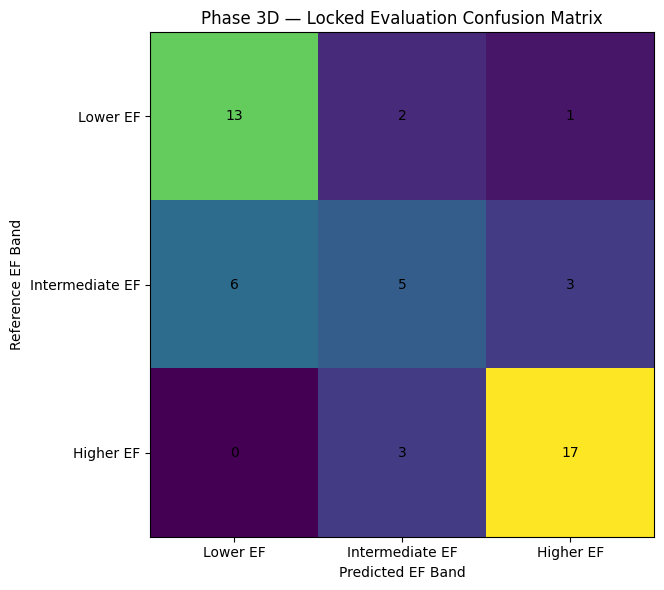

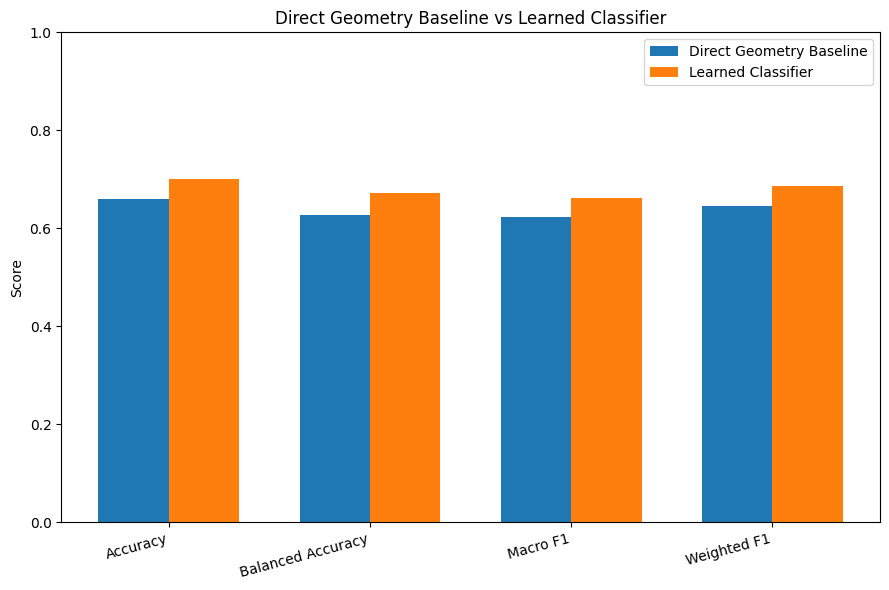

✓ Final Phase 3D figures saved.


In [ ]:
# ================================================================
# PHASE 3D — CELL 15
# FINAL REPORT FIGURES
# ================================================================

# ---------------------------------------------------------------
# FIGURE 1 — CONFUSION MATRIX
# ---------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7, 6)
)


image = ax.imshow(
    test_confusion_matrix
)


ax.set_xticks(
    range(
        len(
            CLASS_ORDER
        )
    )
)


ax.set_yticks(
    range(
        len(
            CLASS_ORDER
        )
    )
)


display_labels = [
    "Lower EF",
    "Intermediate EF",
    "Higher EF"
]


ax.set_xticklabels(
    display_labels
)


ax.set_yticklabels(
    display_labels
)


ax.set_xlabel(
    "Predicted EF Band"
)


ax.set_ylabel(
    "Reference EF Band"
)


ax.set_title(
    "Phase 3D — Locked Evaluation Confusion Matrix"
)


for row in range(
    len(
        CLASS_ORDER
    )
):

    for column in range(
        len(
            CLASS_ORDER
        )
    ):

        ax.text(
            column,
            row,
            int(
                test_confusion_matrix[
                    row,
                    column
                ]
            ),
            ha="center",
            va="center"
        )


fig.tight_layout()


CONFUSION_PLOT_PATH = (
    PHASE3D_PLOT_DIR /
    "phase3D_confusion_matrix.png"
)


fig.savefig(
    CONFUSION_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


# ---------------------------------------------------------------
# FIGURE 2 — BASELINE vs LEARNED
# ---------------------------------------------------------------

comparison_plot_df = (
    comparison_df[
        comparison_df[
            "metric"
        ]
        !=
        "Cohen Kappa"
    ]
    .copy()
)


x_positions = np.arange(
    len(
        comparison_plot_df
    )
)


bar_width = 0.35


fig, ax = plt.subplots(
    figsize=(9, 6)
)


ax.bar(
    x_positions
    -
    bar_width / 2,

    comparison_plot_df[
        "Direct_Geometry_Baseline"
    ],

    width=bar_width,

    label="Direct Geometry Baseline"
)


ax.bar(
    x_positions
    +
    bar_width / 2,

    comparison_plot_df[
        "Learned_Classifier"
    ],

    width=bar_width,

    label="Learned Classifier"
)


ax.set_xticks(
    x_positions
)


ax.set_xticklabels(
    comparison_plot_df[
        "metric"
    ],
    rotation=15,
    ha="right"
)


ax.set_ylim(
    0,
    1
)


ax.set_ylabel(
    "Score"
)


ax.set_title(
    "Direct Geometry Baseline vs Learned Classifier"
)


ax.legend()


fig.tight_layout()


COMPARISON_PLOT_PATH = (
    PHASE3D_PLOT_DIR /
    "phase3D_baseline_vs_learned.png"
)


fig.savefig(
    COMPARISON_PLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print(
    "✓ Final Phase 3D figures saved."
)

In [ ]:
# ================================================================
# PHASE 3D — CELL 16
# FREEZE FINAL PHASE 3D RECORD
# ================================================================

PHASE3D_RECORD_PATH = (
    PHASE3D_CONFIG_DIR /
    "phase3D_final_evaluation_record.json"
)


phase3D_record = {

    "phase":
        "Phase 3D — Final Locked Evaluation",

    "status":
        "COMPLETE_AND_FROZEN",

    "evaluation_set": {

        "n_patients":
            50,

        "role":
            "locked final evaluation set",

        "historical_note":
            (
                "This partition had historical pilot exposure "
                "earlier in the overall project; therefore it "
                "is not described as a pristine external or "
                "never-seen test cohort."
            )
    },

    "classification_target": {

        "Lower_EF":
            "reference EF <= 40%",

        "Intermediate_EF":
            "40% < reference EF < 50%",

        "Higher_EF":
            "reference EF >= 50%"
    },

    "learned_classifier": {

        "selected_feature_set":
            SELECTED_FEATURE_SET,

        "features":
            SELECTED_FEATURES,

        "model_path":
            str(
                PHASE3C_MODEL_PATH
            ),

        "model_sha256":
            ACTUAL_MODEL_SHA256,

        "training_or_tuning_in_phase3D":
            False
    },

    "final_learned_classifier_metrics": {

        "accuracy":
            float(
                test_accuracy
            ),

        "balanced_accuracy":
            float(
                test_balanced_accuracy
            ),

        "macro_f1":
            float(
                test_macro_f1
            ),

        "weighted_f1":
            float(
                test_weighted_f1
            ),

        "cohen_kappa":
            float(
                test_kappa
            ),

        "correct":
            int(
                test_correct
            ),

        "incorrect":
            int(
                test_incorrect
            )
    },

    "confusion_matrix": {

        "class_order":
            CLASS_ORDER,

        "matrix":
            test_confusion_matrix.tolist()
    },

    "per_class_metrics":
        test_per_class_df.to_dict(
            orient="records"
        ),

    "direct_geometry_baseline": {

        "accuracy":
            float(
                baseline_accuracy
            ),

        "balanced_accuracy":
            float(
                baseline_balanced_accuracy
            ),

        "macro_f1":
            float(
                baseline_macro_f1
            ),

        "weighted_f1":
            float(
                baseline_weighted_f1
            ),

        "cohen_kappa":
            float(
                baseline_kappa
            )
    },

    "learned_minus_baseline": {

        "accuracy":
            float(
                test_accuracy
                -
                baseline_accuracy
            ),

        "balanced_accuracy":
            float(
                test_balanced_accuracy
                -
                baseline_balanced_accuracy
            ),

        "macro_f1":
            float(
                test_macro_f1
                -
                baseline_macro_f1
            ),

        "weighted_f1":
            float(
                test_weighted_f1
                -
                baseline_weighted_f1
            ),

        "cohen_kappa":
            float(
                test_kappa
                -
                baseline_kappa
            )
    },

    "error_analysis": {

        "total_misclassifications":
            int(
                len(
                    misclassified_test_df
                )
            ),

        "adjacent_band_errors":
            int(
                adjacent_errors
            ),

        "two_band_errors":
            int(
                two_band_errors
            )
    },

    "protocol_integrity": {

        "classifier_retrained_on_test":
            False,

        "feature_set_changed_after_test":
            False,

        "classification_thresholds_changed":
            False,

        "test_based_calibration":
            False,

        "post_test_model_selection":
            False
    },

    "interpretation":
        (
            "The frozen learned classifier achieved higher "
            "performance than the frozen direct geometry "
            "baseline on the locked 50-patient evaluation set. "
            "Macro F1 increased from 0.6241 to 0.6629. "
            "The Intermediate EF band remained the most "
            "challenging class. Results are interpreted as "
            "assistive research performance and not as evidence "
            "of clinical diagnostic validity."
        )
}


with open(
    PHASE3D_RECORD_PATH,
    "w"
) as file:

    json.dump(
        phase3D_record,
        file,
        indent=2
    )


# ---------------------------------------------------------------
# RELOAD + VERIFY
# ---------------------------------------------------------------

with open(
    PHASE3D_RECORD_PATH,
    "r"
) as file:

    verification_record = (
        json.load(
            file
        )
    )


assert (
    verification_record[
        "status"
    ]
    ==
    "COMPLETE_AND_FROZEN"
)


assert (
    verification_record[
        "protocol_integrity"
    ][
        "classifier_retrained_on_test"
    ]
    is False
)


assert (
    verification_record[
        "protocol_integrity"
    ][
        "post_test_model_selection"
    ]
    is False
)


print("=" * 80)
print("PHASE 3D — FINAL FREEZE")
print("=" * 80)


print(
    "\nFinal Accuracy          :",
    f"{test_accuracy:.4f}"
)


print(
    "Final Balanced Accuracy :",
    f"{test_balanced_accuracy:.4f}"
)


print(
    "Final Macro F1          :",
    f"{test_macro_f1:.4f}"
)


print(
    "Final Weighted F1       :",
    f"{test_weighted_f1:.4f}"
)


print(
    "Final Cohen Kappa       :",
    f"{test_kappa:.4f}"
)


print(
    "\nBaseline Macro F1       :",
    f"{baseline_macro_f1:.4f}"
)


print(
    "Learned Macro F1        :",
    f"{test_macro_f1:.4f}"
)


print(
    "Difference              :",
    f"{test_macro_f1 - baseline_macro_f1:+.4f}"
)


print(
    "\nRecord saved:"
)

print(
    PHASE3D_RECORD_PATH
)


print("\n" + "=" * 80)

print(
    "PHASE 3D STATUS: COMPLETE AND FROZEN"
)

print("=" * 80)


print(
    "\n✓ No post-test tuning performed."
)

print(
    "✓ Final classification results frozen."
)

PHASE 3D — FINAL FREEZE

Final Accuracy          : 0.7000
Final Balanced Accuracy : 0.6732
Final Macro F1          : 0.6629
Final Weighted F1       : 0.6861
Final Cohen Kappa       : 0.5416

Baseline Macro F1       : 0.6241
Learned Macro F1        : 0.6629
Difference              : +0.0388

Record saved:
/content/drive/MyDrive/CAMUS_FINAL/phase3_classification/phase3D_final_evaluation/configs/phase3D_final_evaluation_record.json

PHASE 3D STATUS: COMPLETE AND FROZEN

✓ No post-test tuning performed.
✓ Final classification results frozen.
